# Task 5 — Account Anomaly Detection

## 0. At a glance
| | |
|---|---|
| **Task** | flag anomalous accounts (binary), 25,889 test accounts, **no labels, no training set** |
| **Metric** | F3 of the anomaly class (recall weighted 9× precision) |
| **Final method** | unsupervised **rule-based detection guided by EDA**: 4 detectors, union = 2,104 accounts |
| **Key insight** | normal accounts have mutually independent features; every injected anomaly type breaks independence in a visible way (sudden change, isolated cluster, joint extremes) |
| **Evidence** | each rule was validated by leaderboard probes; Isolation Forest and an autoencoder were run as baselines and each misses whole groups (§7) |

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata, ks_2samp
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
# notebook runs from the repo root (Kaggle-ML/)
if os.path.basename(os.getcwd()) == "report_notebooks": os.chdir("..")
print("cwd:", os.getcwd())

X = pd.read_csv("cpe342-kaggle-main/05_anomaly_detection/test.csv")
P = [1, 2, 3, 4]

cwd: C:\Users\kiati\Documents\Kaggle-ML


## 1. Problem & metric
- **Prediction:** 1 = anomalous account (takeover, account selling, bot, …), otherwise 0.
- **Metric:** $F_\beta = \frac{(1+\beta^2)\,PR}{\beta^2 P + R}$ with β = 3. Recall dominates.
- **Break-even:** adding a row raises F3 when its probability of being anomalous exceeds about $F/(1+\beta^2) \approx 0.08$. Any rule whose rows are > 8% anomalous is worth including.

## 2. Data

In [2]:
per = sorted({c[:-2] for c in X.columns if c[-2:] in ("_1", "_2", "_3", "_4")})
static = [c for c in X.columns if c[-2:] not in ("_1", "_2", "_3", "_4") and c != "player_id"]
print(X.shape, "| metrics measured in 4 periods:", len(per), "| static columns:", static)
print("missing values per cell: %.1f%%" % (100 * X.isna().mean().mean()))
X[[f"activity_level_{p}" for p in P] + ["behavior_stability", "account_age_days"]].head(3)

(25889, 123) | metrics measured in 4 periods: 29 | static columns: ['account_age_days', 'behavior_stability', 'password_changed', 'vpn_usage', 'suspicious_login_time', 'mass_item_sale']
missing values per cell: 4.8%


,activity_level_1,activity_level_2,activity_level_3,activity_level_4,behavior_stability,account_age_days
0,NaN,0.705434,0.599964,NaN,0.232040,1027.683779
1,1.498139,NaN,NaN,1.395960,0.918705,1450.873210
2,1.063620,1.570410,1.363958,1.408561,0.764911,611.275151


## 3. EDA findings
### 3.1 In normal accounts, features are independent of each other
**Finding:** the pairwise correlation of the 4-period means is near zero for almost every pair of metrics. The few pairs with a higher |r| come from the anomaly groups: once the detected accounts are removed, the largest |r| falls to about 0.03 (checked in §5).

In [3]:
CONT = [b for b in per if b not in ("login_lat", "login_lon", "device_count", "refund_count", "guild_changes")]
F = pd.DataFrame({b: X[[f"{b}_{p}" for p in P]].mean(axis=1) for b in CONT})
F["account_age_days"] = X.account_age_days; F["behavior_stability"] = X.behavior_stability
def abs_corr(D): r = D.corr().abs().to_numpy(); return r[np.triu_indices_from(r, 1)]
r = abs_corr(F)
print("pairs:", len(r), "| median |r| = %.3f | max |r| = %.3f (all accounts)" % (np.median(r), r.max()))

pairs: 325 | median |r| = 0.005 | max |r| = 0.240 (all accounts)


**→ Implication:** any structure, such as a group that changes suddenly, a gap in a histogram, or two features that are extreme together, is a sign of an injected anomaly type and not normal variation. The search below looks for exactly these three patterns.

### 3.2 Pattern 1: a sudden change in periods 3–4
**Finding:** for each metric we measure how far periods 3/4 move from the account's own baseline (mean of periods 1–2), scaled to a robust z (median/MAD). Normal accounts end at about z ≈ 5, while a separate population moves by z > 6 on two or more metrics at once.

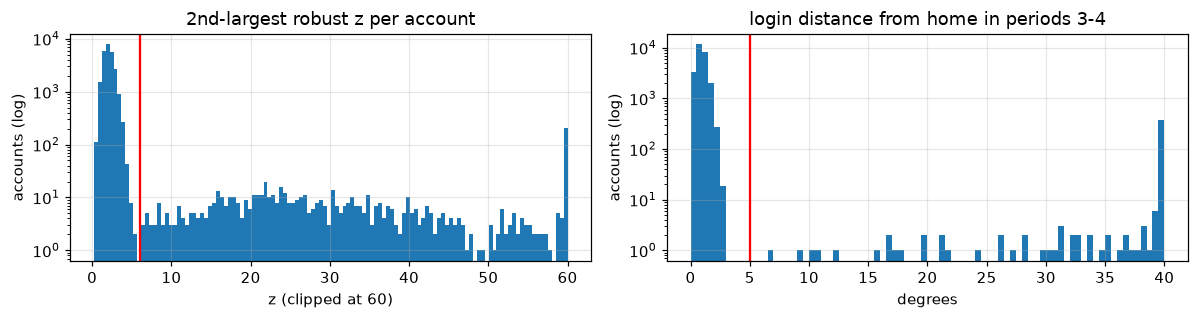

shock accounts: 827 | by metric z: 816 | geo jump: 425 | invalid lat: 71


In [4]:
lat = np.stack([X[f"login_lat_{p}"] for p in P], 1).astype(float); lon = np.stack([X[f"login_lon_{p}"] for p in P], 1).astype(float)
bad_lat = (np.abs(lat) > 90).any(1); lt = np.where(np.abs(lat) > 90, np.nan, lat)
hl, hn = np.nanmean(lt[:, :2], 1), np.nanmean(lon[:, :2], 1)
jump = np.nan_to_num(np.nanmax(np.hypot(lt[:, 2:] - hl[:, None], (lon[:, 2:] - hn[:, None] + 180) % 360 - 180), 1))
Z = []
for b in [b for b in per if b not in ("login_lat", "login_lon")]:
    m = X[[f"{b}_{p}" for p in P]].astype(float).values
    ch = np.nanmax(np.abs(m[:, 2:] - np.nanmean(m[:, :2], 1, keepdims=True)), 1)
    med = np.nanmedian(ch); mad = 1.4826 * np.nanmedian(np.abs(ch - med)) + 1e-9
    Z.append((ch - med) / mad)
Z = np.nan_to_num(np.stack(Z, 1)); z2 = np.sort(Z, 1)[:, -2]          # 2nd-largest z = at least 2 metrics shocked
shock = (jump > 5) | bad_lat | (z2 > 6)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(np.clip(z2, 0, 60), 120, log=True); ax[0].axvline(6, c="r"); ax[0].set(title="2nd-largest robust z per account", xlabel="z (clipped at 60)", ylabel="accounts (log)")
ax[1].hist(np.clip(jump, 0, 40), 80, log=True); ax[1].axvline(5, c="r"); ax[1].set(title="login distance from home in periods 3-4", xlabel="degrees", ylabel="accounts (log)")
plt.tight_layout(); plt.show()
print("shock accounts:", shock.sum(), "| by metric z:", (z2 > 6).sum(), "| geo jump:", (jump > 5).sum(), "| invalid lat:", bad_lat.sum())

**Sub-types.** We split the shock accounts by which period-4 metric is extreme (outside the 0.05%–99.95% range of non-shock accounts). The security flags are never used by the rules, and they confirm the split independently:

In [5]:
def ext(c): v = X[c].values; lo, hi = np.nanquantile(v[~shock], [.0005, .9995]); return (v < lo) | (v > hi)
takeover = shock & (ext("currency_transfers_4") | ext("play_pattern_consistency_4"))
selling = shock & ~takeover & (ext("skill_trajectory_4") | ext("skill_rating_4") | ext("friend_removes_4"))
vpn = shock & ~takeover & ~selling & (ext("purchase_frequency_4") | ext("purchase_amount_mean_4"))
geo = shock & ~takeover & ~selling & ~vpn
flags = ["password_changed", "mass_item_sale", "vpn_usage"]
pd.DataFrame({n: [m.sum()] + list(X.loc[m, flags].mean().round(2)) for n, m in
              [("takeover", takeover), ("selling", selling), ("vpn", vpn), ("geo only", geo), ("not shock", ~shock)]},
             index=["accounts"] + [f"rate {f}" for f in flags]).T

,accounts,rate password_changed,rate mass_item_sale,rate vpn_usage
takeover,310.0,0.99,0.69,0.20
selling,311.0,0.06,0.02,0.15
vpn,198.0,0.03,0.02,1.00
geo only,8.0,0.25,0.29,0.88
not shock,25062.0,0.05,0.02,0.15


- **Takeover:** currency transfers spike or the play pattern breaks. Almost all of these accounts have password_changed, and most have mass_item_sale.
- **Selling:** skill and friend metrics jump. No security flag is raised.
- **VPN:** purchases spike, and every account in this group has vpn_usage.

**→ Implication:** detector A = **shock** (robust z > 6 on ≥ 2 metrics, or geo jump > 5°, or invalid latitude).

### 3.3 Pattern 2: isolated clusters on a single feature
**Finding:** among non-shock accounts, a few features have a histogram with an **empty gap** that cuts off a small cluster.

 265 rows  ['activity_level < 0.345']
 263 rows  ['communication_frequency < 0.169']
 246 rows  ['behavior_stability < 0.473']
 207 rows  ['ip_hash_entropy < 0.238', 'kda_std < 0.151', 'login_time_variance < 1.082', 'session_duration_std < 6.297']


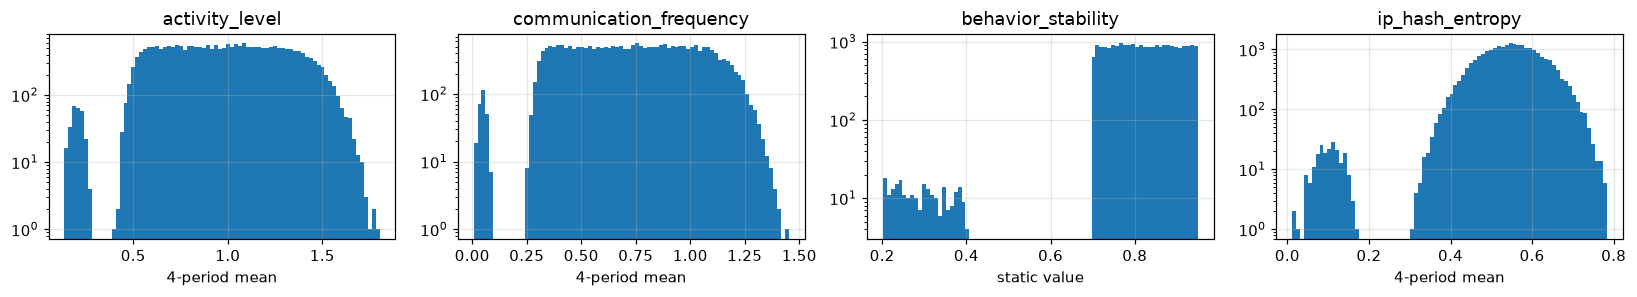

In [6]:
def gap_clusters(v, nb=80, lowfrac=0.02, minrun=3):
    """runs of >= minrun near-empty bins (<= 2% of a typical bin) that cut off a small side (50-2000 rows)"""
    ok = ~np.isnan(v); h, e = np.histogram(v[ok], bins=nb); low = h <= lowfrac * np.median(h[h > 0]); out, i = [], 0
    while i < nb:
        if low[i]:
            j = i
            while j < nb and low[j]: j += 1
            nl, nr = h[:i].sum(), h[j:].sum()
            if j - i >= minrun and i > 0 and j < nb and 50 <= min(nl, nr) <= 2000:
                out.append(((e[i] + e[j]) / 2, -1 if nl < nr else +1))
            i = j
        else: i += 1
    return out
gap = {}
for c in F.columns:
    v = F[c].values.astype(float)
    for cut, side in gap_clusters(np.where(shock, np.nan, v)):
        gap[f"{c} {'<' if side < 0 else '>'} {cut:.3f}"] = (~shock) & ((v < cut) if side < 0 else (v > cut))
groups = []                                     # the same rows seen through several features = one cluster
for k, f in sorted(gap.items(), key=lambda t: -t[1].sum()):
    for g in groups:
        if (f & g["flag"]).sum() > 0.5 * min(f.sum(), g["flag"].sum()): g["rules"].append(k); g["flag"] |= f; break
    else: groups.append({"rules": [k], "flag": f.copy()})
for g in groups: print(f"{int(g['flag'].sum()):4d} rows  {g['rules']}")
groups_by = lambda feat: [g["flag"] for g in groups if any(r.startswith(feat) for r in g["rules"])][0]
fig, ax = plt.subplots(1, 4, figsize=(15, 2.8))
for a, c in zip(ax, ["activity_level", "communication_frequency", "behavior_stability", "ip_hash_entropy"]):
    a.hist(F[c].where(~shock).dropna(), 80, log=True); a.set(title=c, xlabel="4-period mean" if c != "behavior_stability" else "static value")
plt.tight_layout(); plt.show()

The four clusters are:
- **low activity:** activity_level < 0.345
- **low communication:** communication_frequency < 0.169
- **low stability:** behavior_stability below the gap (no account between 0.40 and 0.70; the scan cuts at 0.473)
- **bot:** the same 207 accounts appear in four features at once (ip_hash_entropy, kda_std, login_time_variance, session_duration_std all low)

**→ Implication:** detector B = **gap clusters**. A scan of every feature finds no further gap.

### 3.4 Pattern 3: two features extreme together
**Finding:** on the remaining accounts, each feature's 5% tails should co-occur at the independence rate (5% × 5%). One pair occurs far more often: high accuracy_std with high kda_std.

In [7]:
gapflag = np.zeros(len(X), bool)
for g in groups: gapflag |= g["flag"]
rest = ~shock & ~gapflag; Fr = F[rest]
T = {(c, s): ((Fr[c] < Fr[c].quantile(.05)) if s < 0 else (Fr[c] > Fr[c].quantile(.95))).values for c in F.columns for s in (-1, 1)}
keys = list(T); Tm = np.stack([T[k] for k in keys], 1).astype(float)
cnt = Tm.T @ Tm; pr = Tm.mean(0); E = np.outer(pr, pr) * len(Tm); Zp = np.nan_to_num((cnt - E) / np.sqrt(np.maximum(E, 1e-9)))
pairs = sorted([(Zp[i, j], keys[i], keys[j]) for i in range(len(keys)) for j in range(i + 1, len(keys)) if keys[i][0] != keys[j][0]], key=lambda t: -t[0])
for z, a, b in pairs[:4]: print(f"z = {z:5.1f}   {a} x {b}")
print("median pair z = %.2f" % np.median([p[0] for p in pairs]))

z =  20.9   ('accuracy_std', 1) x ('kda_std', 1)
z =   2.9   ('friend_removes', 1) x ('skill_rating', -1)
z =   2.8   ('activity_level', -1) x ('login_time_variance', 1)
z =   2.7   ('location_changes', -1) x ('account_age_days', 1)
median pair z = 0.00


A 2-component EM (Gaussian cluster vs an independent background) on this pair, expanded with every feature whose cluster mean shifts by > 0.6 sd, adds performance_stability. The box is the per-period range of the confident members (posterior > 0.9). It is computed in `t5/research/t5_pipeline.py` and loaded here:

box: {'accuracy_std': [8.9588, 12.0298], 'kda_std': [0.6962, 1.0042], 'performance_stability': [0.8486, 0.9514]} | accounts inside: 244 | EM cluster share: 0.94%


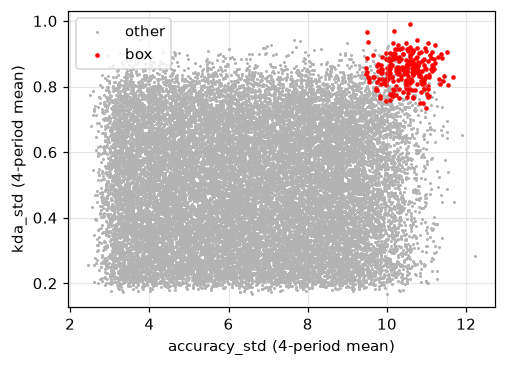

In [8]:
summ = json.load(open("work/t5v2/out/t5_pipeline_summary.json")); bounds = summ["components"][0]["box"]
inbox = rest.copy()
for c, (lo, hi) in bounds.items():
    m = X[[f"{c}_{p}" for p in P]].values.astype(float); inbox &= (((m >= lo) & (m <= hi)) | np.isnan(m)).all(1)
print("box:", bounds, "| accounts inside:", inbox.sum(), "| EM cluster share: %.2f%%" % (100 * summ["components"][0]["pi"]))
plt.figure(figsize=(5, 3.5)); s = rest & ~inbox
plt.scatter(F.accuracy_std[s], F.kda_std[s], s=1, c="0.7", label="other"); plt.scatter(F.accuracy_std[inbox], F.kda_std[inbox], s=4, c="r", label="box")
plt.xlabel("accuracy_std (4-period mean)"); plt.ylabel("kda_std (4-period mean)"); plt.legend(); plt.show()

**→ Implication:** detector C = **acc/kda box**. This group is invisible on any single feature and only shows up in the joint view.

### 3.5 Missing values hide members of the low-stability cluster
**Finding:** the low-stability rule reads one static column, and that column is NaN for about 5% of accounts. Some cluster members must therefore be hidden.

In [9]:
ls = groups[[i for i, g in enumerate(groups) if any("behavior_stability" in r for r in g["rules"])][0]]["flag"]
u = shock | gapflag | inbox; bsn = X.behavior_stability.isna().values
print("NaN behavior_stability: %.1f%% | expected hidden members = %d x %.3f / %.3f = %.0f"
      % (100 * bsn.mean(), ls.sum(), bsn.mean(), 1 - bsn.mean(), ls.sum() * bsn.mean() / (1 - bsn.mean())))
def allin(b, lo, hi):
    m = X[[f"{b}_{p}" for p in P] if b != "account_age_days" else [b]].values.astype(float); return (((m >= lo) & (m <= hi)) | np.isnan(m)).all(1)
pf, age = allin("purchase_frequency", 3, 6), allin("account_age_days", 800, 1500)
print("members inside purchase_frequency[3,6] & age[800,1500]: %.0f%%" % (100 * (pf & age)[ls].mean()))
cand = bsn & ~u & pf & age; chance = (pf & age)[~u & ~bsn].mean() * (bsn & ~u).sum()
print(f"NaN accounts inside these ranges: {cand.sum()} observed vs {chance:.0f} expected by chance")

NaN behavior_stability: 4.9% | expected hidden members = 246 x 0.049 / 0.951 = 13
members inside purchase_frequency[3,6] & age[800,1500]: 100%
NaN accounts inside these ranges: 128 observed vs 109 expected by chance


**→ Implication:** detector D = **hidden low-stability members**. Candidates are scored with a naive-Bayes posterior that uses two other traits of the cluster: low mean login_count and high period-to-period variation in purchase_frequency.

## 4. Method
**Approach:** unsupervised, rule-based detection guided by EDA. No model is trained to predict anomalies because there are no labels. Each detector is a statistical test with a threshold:

| Detector | Technique | Threshold | Why it is valid |
|---|---|---|---|
| A. Shock | robust z (median/MAD) of the period-3/4 change; geo distance | z > 6 on ≥ 2 metrics; > 5° | normal accounts end at z ≈ 5, with an empty band before 6 (§3.2) |
| B. Gap clusters | histogram gap scan on 4-period means and static fields | cut inside the empty gap | the gap is empty, so the cut is unambiguous (§3.3) |
| C. Joint box | 5%-tail co-occurrence z-test → EM → per-period box | inside all box ranges | z = 20.9 vs a median near 0 (§3.4) |
| D. Hidden lowstab | naive-Bayes posterior (2 features + prior) | posterior > 0.1 | F3 break-even ≈ 0.08 (§1) |

**Final prediction** = A ∪ B ∪ C ∪ D.

**Why rules and not an anomaly-detection model:**
- **No labels:** a model's score would still need a threshold chosen without feedback.
- **The groups have hard edges:** rules capture them exactly.
- **The baselines lost** (§7).

## 5. Implementation (final set)

In [10]:
# D: posterior for NaN-stability candidates (same computation as t5_box_analysis.py, section 5)
lm = X[[f"login_count_{p}" for p in P]].mean(axis=1).values; ps = X[[f"purchase_frequency_{p}" for p in P]].std(axis=1).values
nor = ~u & ~bsn & pf & age & (X.behavior_stability.values >= 0.6)
def logpdf(v, ref, bins):
    h, _ = np.histogram(ref[~np.isnan(ref)], bins=bins); h = (h + .5) / (h.sum() + .5 * len(h)) / np.diff(bins)
    o = np.log(h[np.clip(np.digitize(v, bins) - 1, 0, len(h) - 1)]); o[np.isnan(v)] = 0; return o
bl, bp = np.linspace(0, 130, 27), np.linspace(0, 2.5, 26)
LLR = logpdf(lm, lm[ls], bl) - logpdf(lm, lm[nor], bl) + logpdf(ps, ps[ls], bp) - logpdf(ps, ps[nor], bp)
HIDDEN = 14            # prior: expected hidden members (submitted v25a; the estimate on this data is 13, see section 6)
prior = HIDDEN / cand.sum(); post = np.where(cand, 1 / (1 + np.exp(-(LLR + np.log(prior / (1 - prior))))), 0)
lsnan = post > 0.1
final = shock | gapflag | inbox | lsnan
sets = {"A shock": shock, "B gap clusters": gapflag, "C acc/kda box": inbox, "D hidden lowstab": lsnan}
print("overlap between detectors:", sum((a & b).sum() for i, a in enumerate(sets.values()) for b in list(sets.values())[i + 1:]), "accounts")
pd.Series({**{k: v.sum() for k, v in sets.items()}, "union (final)": final.sum()}, name="accounts").to_frame()

overlap between detectors: 0 accounts


,accounts
A shock,827
B gap clusters,981
C acc/kda box,244
D hidden lowstab,52
union (final),2104


In [11]:
sub = pd.read_csv("t5/preds/v2data/t5v2_union_box_lsnan.csv")
assert (sub.pred.values == final.astype(int)).all(); print("matches the submitted T5 predictions (sub_v25a):", final.sum(), "accounts")
print("independence check on the remaining accounts: max |r| = %.3f (was %.3f with all accounts)" % (abs_corr(F[~final]).max(), abs_corr(F).max()))

matches the submitted T5 predictions (sub_v25a): 2104 accounts
independence check on the remaining accounts: max |r| = 0.026 (was 0.240 with all accounts)


## 6. Validation & results
There are no labels, so every design decision was tested with a leaderboard submission that changes only T5 (public LB, original data release):

| Test | Public LB change | Conclusion |
|---|---|---|
| T5 set to all 0 | −0.177 | T5 carries real weight, so the score reacts to T5 changes |
| union + looser rules (3,602 rows) | −0.012 | rows outside the rules are almost all normal |
| + shock z 4–6, geo 2–5° (+356 rows) | −0.0025 | the z > 6 / 5° thresholds sit at the edge of the groups |
| hidden-lowstab posterior cut 0.15 instead of 0.10 | −0.00012 | the dropped rows held true anomalies |
| cut 0.05 instead of 0.10 | +0.00002 | flat, so keep 0.10 |
| re-released data (12 Nov), same pipeline | full submission 0.85787 (best) | the method transfers to new data (sizes below) |

Group sizes found by the same pipeline on the original and the re-released test data:

| Data | shock | bot | low activity | low comm. | low stability | acc/kda box | hidden lowstab | union |
|---|---|---|---|---|---|---|---|---|
| original (5–7 Nov) | 827 | 207 | 266 | 237 | 274 | 244 | 48 | 2,103 |
| re-released (12 Nov, this notebook) | 827 | 207 | 265 | 263 | 246 | 244 | 52 | 2,104 |

**Sensitivity:** on the re-released data the prior for D is estimated at 13 instead of 14, which removes 6 rows (`sub_v27_T5prior13.csv`, expected LB effect ≈ 0.0001).

## 7. What did not work (baselines)
We ran the two anomaly-scoring models on the same data. Each was allowed to flag as many accounts as our final set (its top 2,104), and the table shows how much of each detected group it catches:

In [12]:
from sklearn.ensemble import IsolationForest
feat = pd.concat([((F - F.median()) / (F.quantile(.75) - F.quantile(.25))).fillna(0),
                  pd.DataFrame(np.clip(Z, -50, 50) / 10), pd.Series(np.clip(jump, 0, 50) / 10, name="jump")], axis=1)
feat.columns = feat.columns.astype(str)
iso = -IsolationForest(n_estimators=500, max_samples=1024, random_state=0, n_jobs=-1).fit(feat).score_samples(feat)
tmae = pd.read_csv("work/t5v2/tmae/task5_tmae_scores.csv").tmae.values     # t5/code/task5_tmae.py on this data (CPU, ~20 min)
K = final.sum(); topk = lambda sc: sc >= np.sort(sc)[-K]
G = {"takeover": takeover, "selling": selling, "vpn": vpn, "bot": groups_by("ip_hash_entropy"), "low activity": groups_by("activity_level"),
     "low communication": groups_by("communication_frequency"), "low stability": ls, "acc/kda box": inbox & ~shock & ~gapflag,
     "hidden lowstab": lsnan & ~(shock | gapflag | inbox)}
cap = pd.DataFrame({name: {g: "%.0f%%" % (100 * topk(sc)[m].mean()) for g, m in G.items()} for name, sc in [("Isolation Forest", iso), ("autoencoder (TMAE)", tmae)]})
cap.loc[f"accounts outside our final set, in its top {K}"] = ["%d" % (topk(sc) & ~final).sum() for sc in (iso, tmae)]
cap

,Isolation Forest,autoencoder (TMAE)
takeover,99%,55%
selling,100%,6%
vpn,100%,33%
bot,100%,6%
low activity,13%,5%
low communication,18%,9%
low stability,32%,8%
acc/kda box,10%,10%
hidden lowstab,0%,15%
"accounts outside our final set, in its top 2104",888,1743


Neither model is a usable replacement. Each one misses whole groups:

| Method | Groups it catches | Groups it misses | Why |
|---|---|---|---|
| Isolation Forest | all shock sub-types (takeover, selling, VPN) and bots | most of low activity, low communication, low stability, the acc/kda box, and the hidden low-stability members | these accounts are extreme on only one or two features and normal on the rest, so random splits do not isolate them early; their places in the top 2,104 go to accounts outside our set |
| Autoencoder (TMAE) | about half of the takeovers and a third of the VPN group | selling, bots, every stationary cluster and the acc/kda box | a stationary group is consistent across all 4 periods, so the model reconstructs it well and gives it a low error; noisy normal accounts fill most of its top 2,104 |
| Gaussian-EM posterior instead of the box | the acc/kda group | — (replaced) | the box has sharper edges; the posterior adds border noise |
| Looser thresholds / extra top-scored rows | — | — | public LB −0.012 (§6): the extra rows are mostly normal |

## 8. Output & reproducibility
- **Predictions:** `t5/preds/v2data/t5v2_union_box_lsnan.csv` (`id`, `pred`), in test.csv row order, 2,104 positives.
- **Scripts:**
  - `t5/research/t5_pipeline.py` (detectors A–C plus the Isolation Forest check)
  - `t5/research/t5_box_analysis.py` (box checks, sub-types, completeness search, detector D)
- **Rebuild:** `python report_notebooks/build_t5.py` regenerates and runs this notebook in about 1 minute.